---
title: "Plotting with PyMC and Arviz"
author: "Sheng Long"
date: "12/18/25"
draft: true 
---

:::{.callout-note}
# TLDR 

This post is about trying to answer a simple question: to what extent does existing functionalities of `pymc` and `arviz` implement what can be done in `tidybayes` ...? 

Trying to implement the examples [here](https://mjskay.github.io/tidybayes/articles/tidy-brms.html). 

:::


In [59]:
import arviz as az 
import pandas as pd 
import pymc as pm 
import numpy as np 
import matplotlib.pyplot as plt
az.style.use("arviz-docgrid")

In [60]:
RANDOM_SEED = 5
rng = np.random.default_rng(RANDOM_SEED)
n = 10
n_condition = 5
ABC = pd.DataFrame(rng.normal([0, 1, 2, 1, -1], scale=0.5, size=(n, n_condition))).set_axis(['A', 'B', 'C', 'D', 'E'], axis='columns')
ABC = pd.melt(ABC)

A snapshot of the data looks like this: 

In [61]:
ABC.head(10)

,variable,value
0,A,-0.400966
1,A,0.054853
2,A,0.136384
3,A,-0.866067
4,A,-0.356657
5,A,0.414928
6,A,-0.644709
7,A,-0.198095
8,A,0.585148
9,A,0.016529


We can try to plot is as follows: 

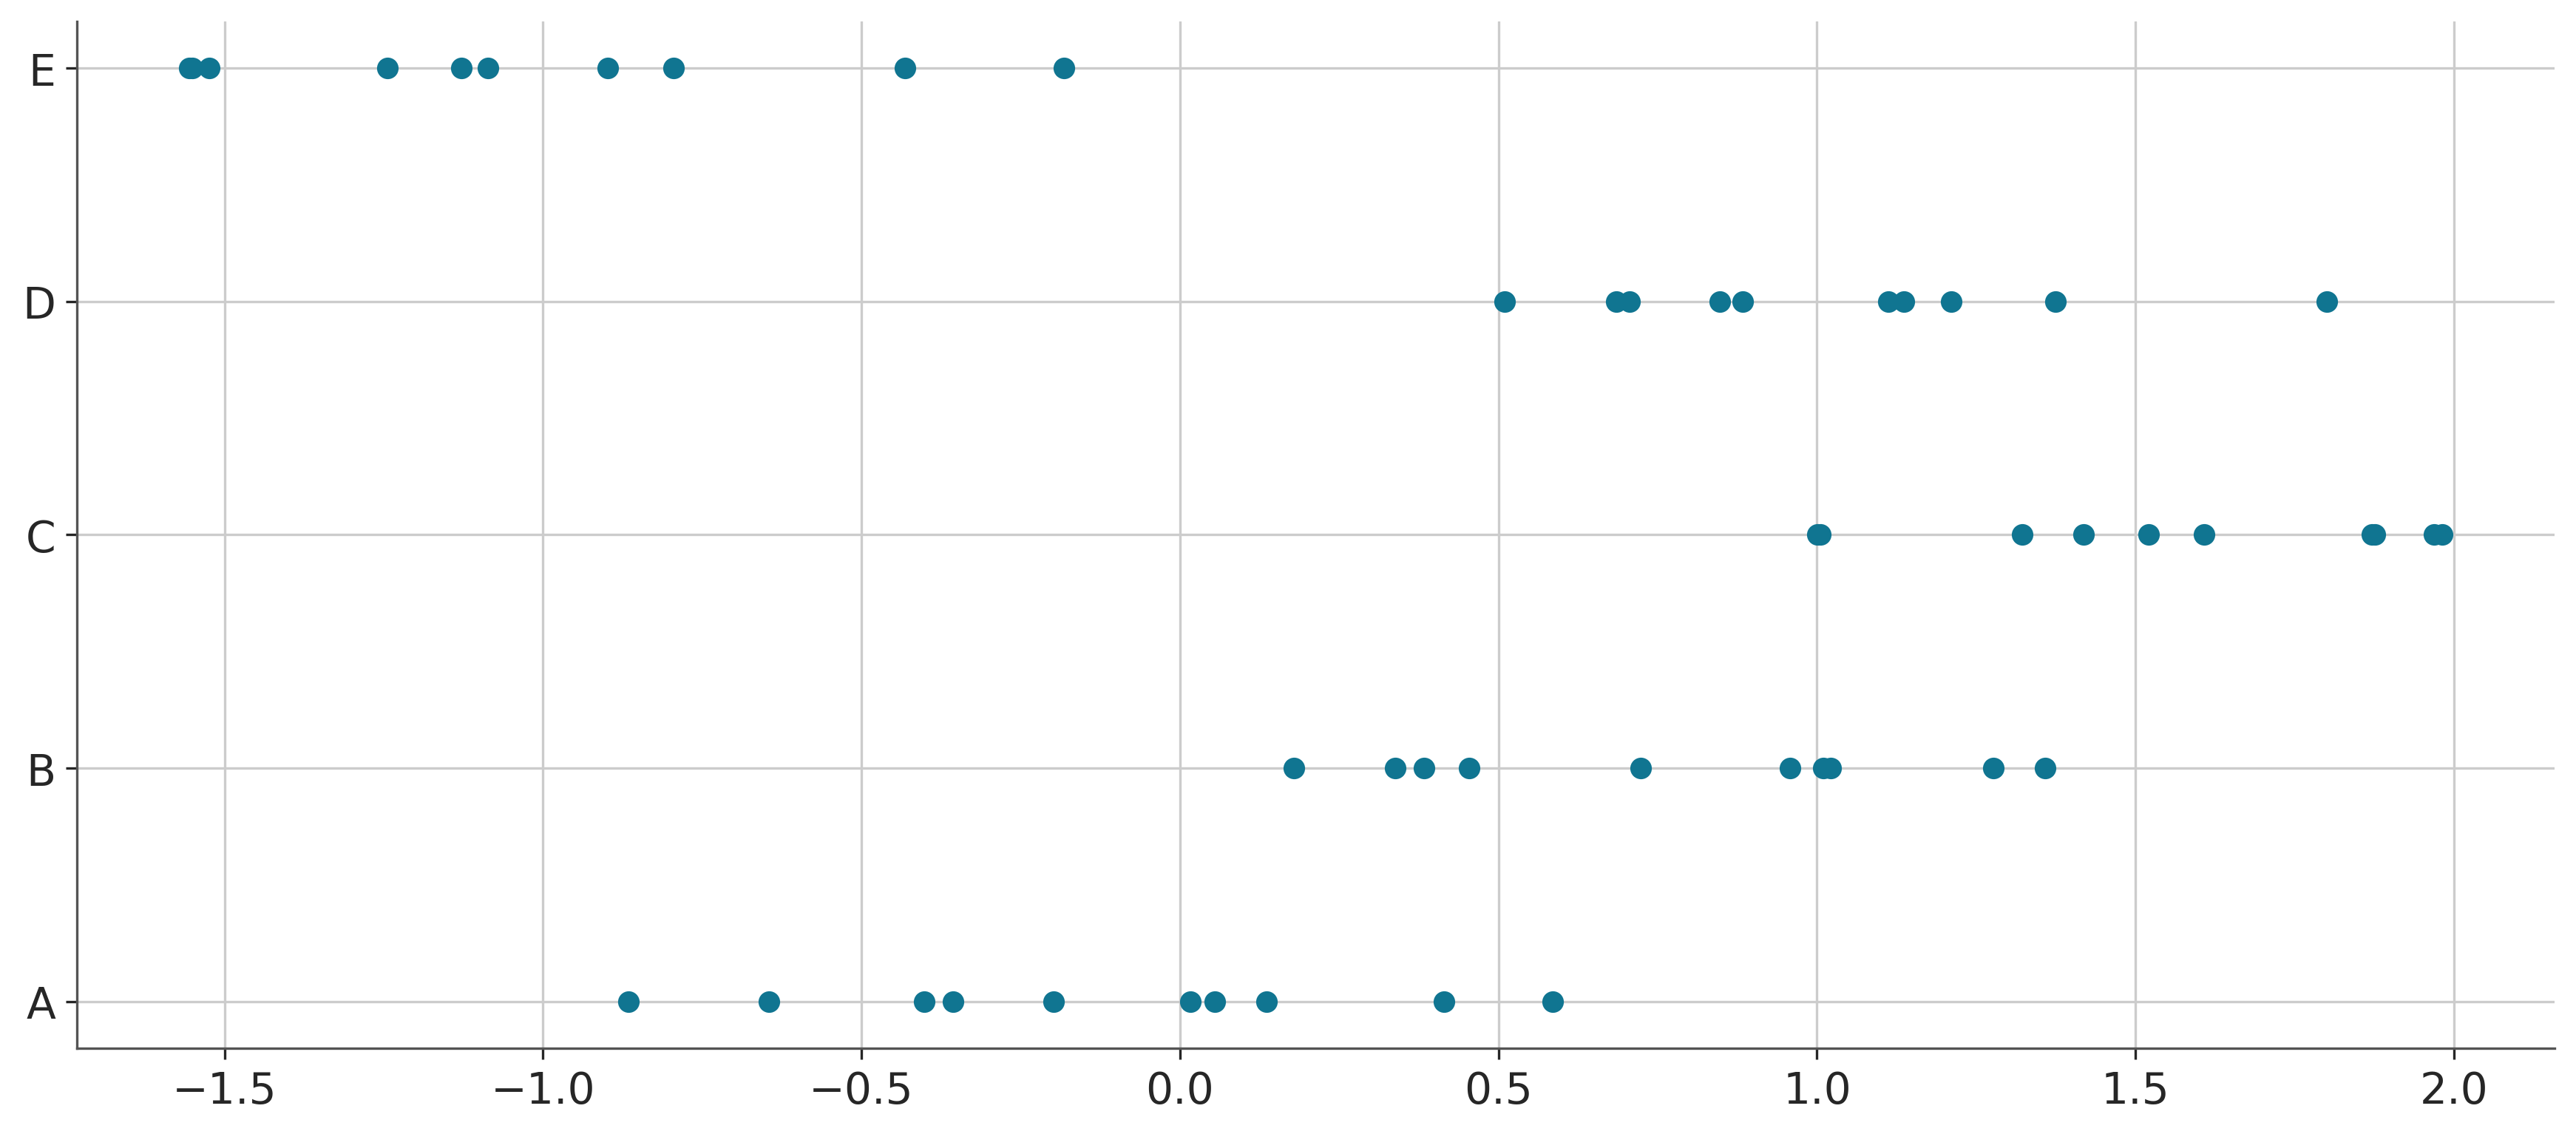

In [62]:
fig, ax = plt.subplots()
ax.scatter(data=ABC, x = "value", y = "variable")

## Model

We can fit a hierarchical model with shrinkage towards a global mean. The mathematical formulation is as follows: 

$$
\begin{align}
\texttt{value} &\sim \mathcal{N}(\alpha_{\text{variable}[i]}, \sigma) \\
\alpha_j &\sim \mathcal{N}(\bar{\alpha}, \sigma_\alpha), j \in [5] \\ 
\bar{\alpha} &\sim \mathcal{N}(0, 1) \\ 
\sigma_\alpha &\sim \text{student-t}^+(3, 0, 1) \\  
\sigma &\sim \text{student-t}^+(3, 0, 1) \\ 
\end{align}
$$

In [63]:
var_idx, var_value = pd.factorize(ABC['variable'])
coords = {
    'var': var_value
}

In [64]:
with pm.Model(coords=coords) as ABC_model:
    # priors and hyperpriors 
    alpha_bar = pm.Normal("alpha_bar", 0, 1)
    sigma_alpha = pm.HalfStudentT("sigma_alpha", nu=3, sigma=1)
    sigma = pm.HalfStudentT("sigma", nu=3, sigma=1)
    # likelihood ...? 
    alpha = pm.Normal("alpha", alpha_bar, sigma_alpha, dims="var")
    y_obs = pm.Normal("y_obs", mu=alpha[var_idx],sigma=sigma,observed=ABC['value'])


In [65]:
with ABC_model:
    idata = pm.sample(progressbar=False)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha_bar, sigma_alpha, sigma, alpha]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 19 seconds.


Note that in some of the tutorials, they refer to this as `idata`, perhaps a shorthand for the `InferenceData` object^[See [official document](https://python.arviz.org/en/latest/getting_started/XarrayforArviZ.html) for more details]. In some other tutorials you would see this being referred to as `XXXX_trace`. Put simply, it is a container for groups of data. 

In [66]:
idata

[autoreload of cutils_ext failed: Traceback (most recent call last):
  File "/Users/shenglong/Downloads/mika-long.github.io/.venv/lib/python3.13/site-packages/IPython/extensions/autoreload.py", line 325, in check
    superreload(m, reload, self.old_objects)
    ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/shenglong/Downloads/mika-long.github.io/.venv/lib/python3.13/site-packages/IPython/extensions/autoreload.py", line 580, in superreload
    module = reload(module)
  File "/Users/shenglong/.local/share/uv/python/cpython-3.13.9-macos-x86_64-none/lib/python3.13/importlib/__init__.py", line 128, in reload
    raise ModuleNotFoundError(f"spec not found for the module {name!r}", name=name)
ModuleNotFoundError: spec not found for the module 'cutils_ext'
]


Inference data with groups:
	> posterior
	> sample_stats
	> observed_data

In this case, the `InferenceData`^[In the example in the original documentation, it also has `posterior_predictive` and `prior`] has contains three "datasets": `posterior`, `sample_stats`, and `observed_data`. 

We could access the posterior draws simply by directly referencing it: 

In [73]:
print(idata.posterior)
print(type(idata.posterior))

<xarray.Dataset> Size: 264kB
Dimensions:      (chain: 4, draw: 1000, var: 5)
Coordinates:
  * chain        (chain) int64 32B 0 1 2 3
  * draw         (draw) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
  * var          (var) <U1 20B 'A' 'B' 'C' 'D' 'E'
Data variables:
    alpha_bar    (chain, draw) float64 32kB 0.7988 0.7276 ... 0.4716 0.5919
    alpha        (chain, draw, var) float64 160kB 0.1649 0.8276 ... -1.001
    sigma_alpha  (chain, draw) float64 32kB 1.037 0.8986 0.7145 ... 1.314 0.7436
    sigma        (chain, draw) float64 32kB 0.3592 0.3608 ... 0.4625 0.3943
Attributes:
    created_at:                 2025-12-18T22:07:06.287062+00:00
    arviz_version:              0.22.0
    inference_library:          pymc
    inference_library_version:  5.26.1
    sampling_time:              19.43943190574646
    tuning_steps:               1000
<class 'xarray.core.dataset.Dataset'>


Those who are more familiar with the `tidy data` format might find the above ways of indexing with coordinates and dimensions confusing. We could turn the `Dataset` into a `DataFrame` in tidy form^[See reference documentation [here](https://docs.xarray.dev/en/stable/user-guide/pandas.html)]: 

In [75]:
idata.posterior.to_dataframe().head(10)

alpha_bar     alpha  sigma_alpha     sigma
chain draw var                                            
0     0    A     0.798795  0.164872     1.036728  0.359150
           B     0.798795  0.827576     1.036728  0.359150
           C     0.798795  1.334229     1.036728  0.359150
           D     0.798795  0.954767     1.036728  0.359150
           E     0.798795 -1.032201     1.036728  0.359150
      1    A     0.727635  0.074987     0.898552  0.360805
           B     0.727635  0.731381     0.898552  0.360805
           C     0.727635  1.529692     0.898552  0.360805
           D     0.727635  0.946406     0.898552  0.360805
           E     0.727635 -1.031409     0.898552  0.360805

In [67]:
#| code-fold: true 

# save fitted posterior 
# giidata.to_netcdf("ABC_posterior.nc")

---

`tidybayes` provides functions such as `median_qi()` and `mode_hdi()` for calculating point summaries and intervals. Their equivalent in `arviz` are [`arviz_stats.eti`](https://python.arviz.org/projects/stats/en/stable/api/generated/arviz_stats.eti.html) and [`arviz.hdi`](https://python.arviz.org/en/latest/api/generated/arviz.hdi.html). 

In [89]:
print(az.hdi(idata, var_names=["alpha_bar", "sigma"], hdi_prob = 0.95).to_dataframe())

        alpha_bar     sigma
hdi                        
lower   -0.574370  0.346919
higher   1.308319  0.528288


In [82]:
import arviz_stats as avz 

In [87]:
avz.eti(idata, var_names=["alpha_bar", "sigma"], prob = 0.95).to_dataframe()

,alpha_bar,sigma
ci_bound,,
lower,-0.592632,0.352223
upper,1.290091,0.536236


We can also get a table of summary statistics with the [`arviz.summary`](https://python.arviz.org/en/stable/api/generated/arviz.summary.html) function: 

In [91]:
az.summary(idata, stat_focus="median", hdi_prob=0.95)

,median,mad,eti_2.5%,eti_97.5%,mcse_median,ess_median,ess_tail,r_hat
alpha_bar,0.367,0.306,-0.593,1.290,0.008,4272.107,2404.0,1.0
alpha[A],-0.115,0.089,-0.385,0.152,0.002,5423.275,2903.0,1.0
alpha[B],0.757,0.088,0.499,1.024,0.002,4692.825,3062.0,1.0
alpha[C],1.530,0.089,1.265,1.806,0.002,5169.563,3147.0,1.0
alpha[D],1.015,0.090,0.742,1.272,0.003,4640.295,2776.0,1.0
alpha[E],-1.016,0.090,-1.284,-0.733,0.003,5131.215,3237.0,1.0
sigma_alpha,1.043,0.224,0.601,2.238,0.006,3460.928,2362.0,1.0
sigma,0.426,0.032,0.352,0.536,0.001,4113.274,3118.0,1.0


In [95]:
az.summary(idata, stat_focus="mean", hdi_prob=0.95)

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha_bar,0.359,0.477,-0.574,1.308,0.008,0.010,3632.0,2404.0,1.0
alpha[A],-0.117,0.135,-0.364,0.170,0.002,0.002,5170.0,2903.0,1.0
alpha[B],0.760,0.133,0.504,1.027,0.002,0.002,4871.0,3062.0,1.0
alpha[C],1.532,0.137,1.269,1.810,0.002,0.002,5601.0,3147.0,1.0
alpha[D],1.012,0.135,0.757,1.284,0.002,0.002,4985.0,2776.0,1.0
alpha[E],-1.014,0.137,-1.266,-0.721,0.002,0.002,4918.0,3237.0,1.0
sigma_alpha,1.138,0.434,0.524,1.966,0.009,0.014,3212.0,2362.0,1.0
sigma,0.431,0.047,0.347,0.528,0.001,0.001,4120.0,3118.0,1.0


array([<Axes: title={'center': '95.0% HDI'}>], dtype=object)

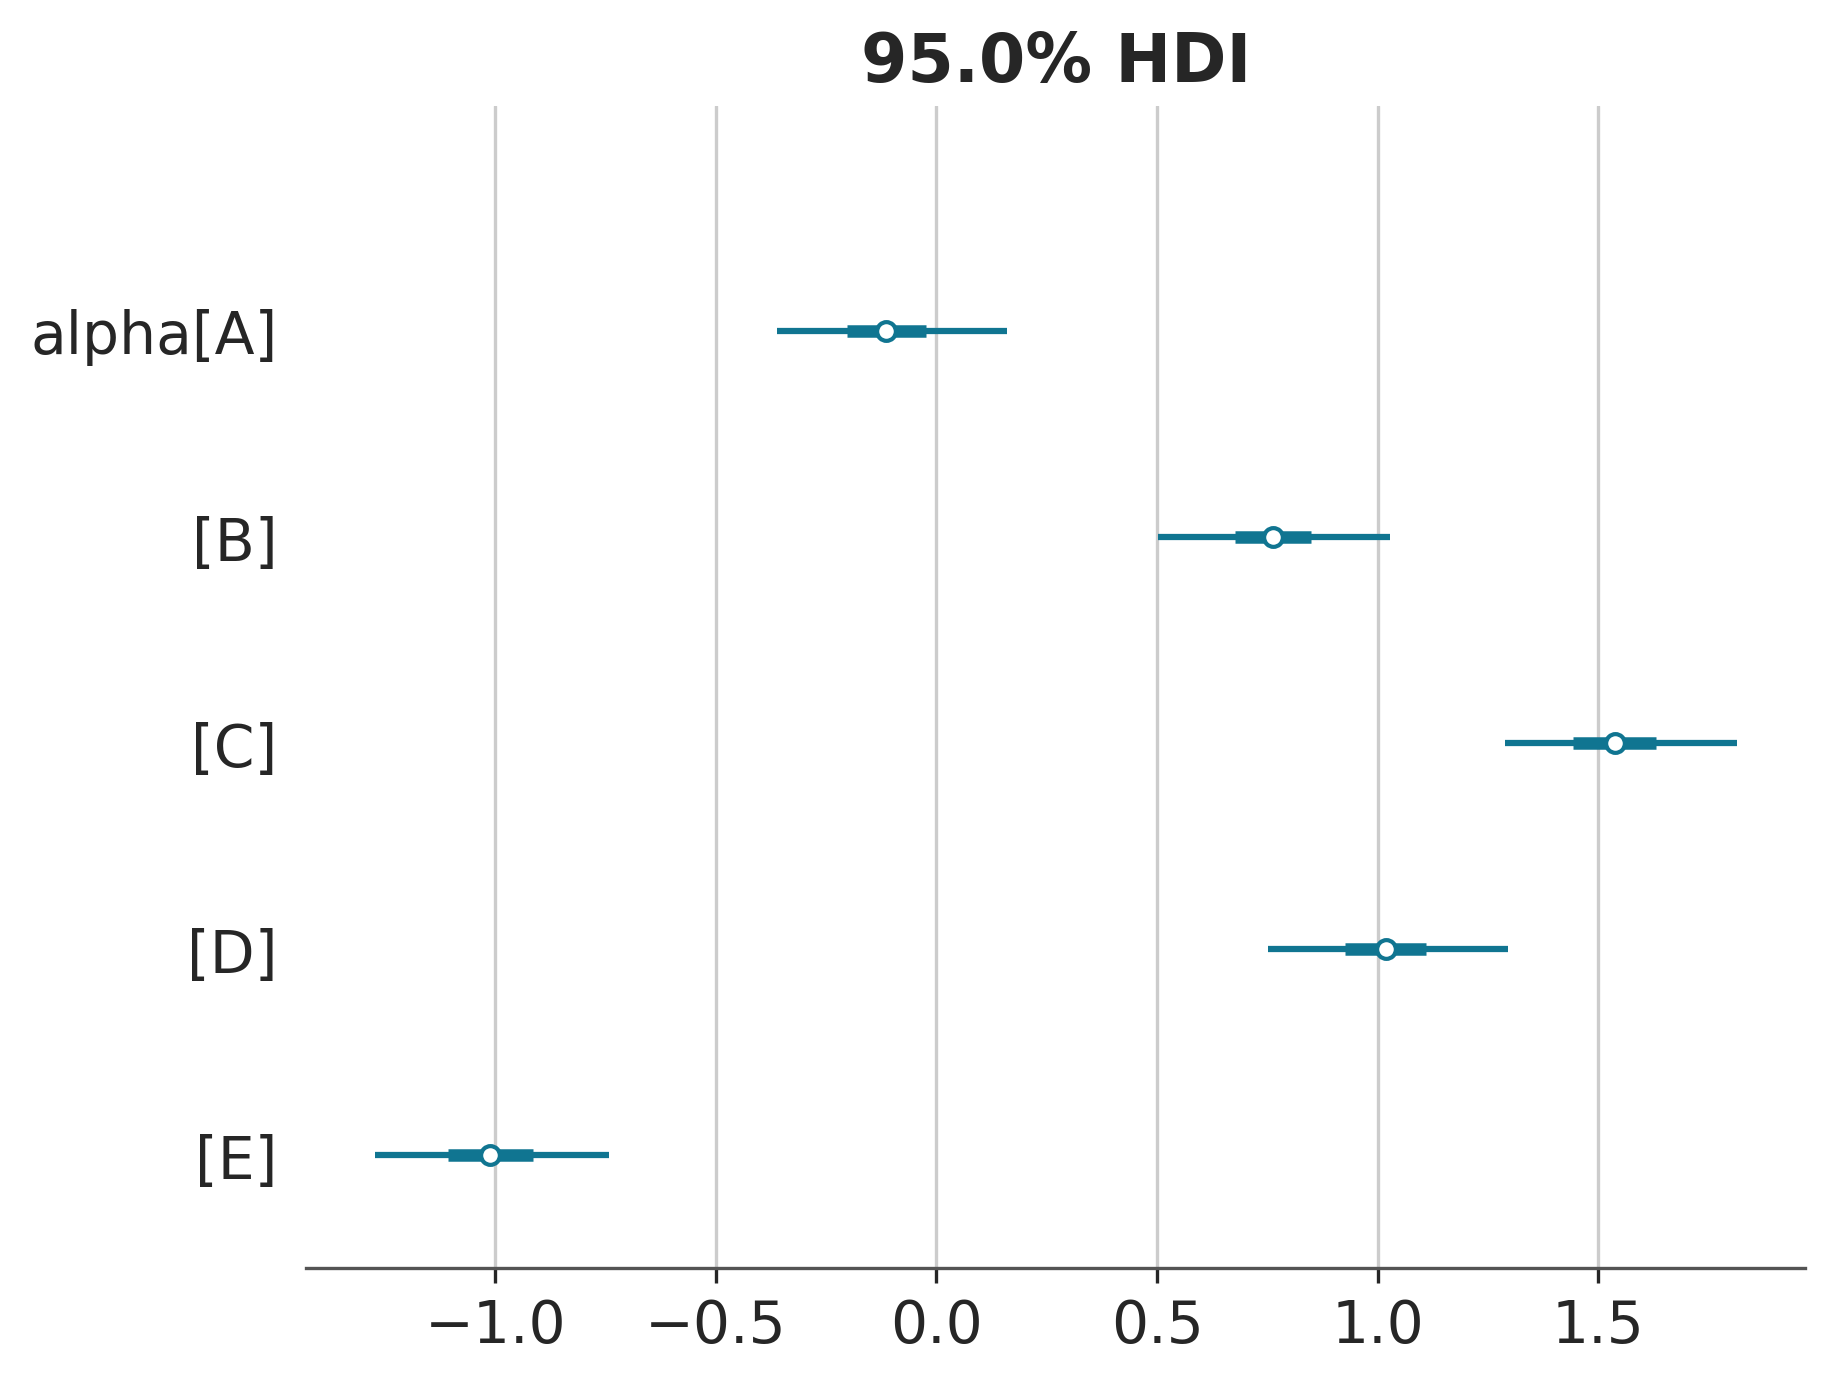

In [51]:
az.plot_forest(idata, combined=True, var_names=["alpha"], hdi_prob=0.95)

## Intervals with densities 

array([<Axes: >], dtype=object)

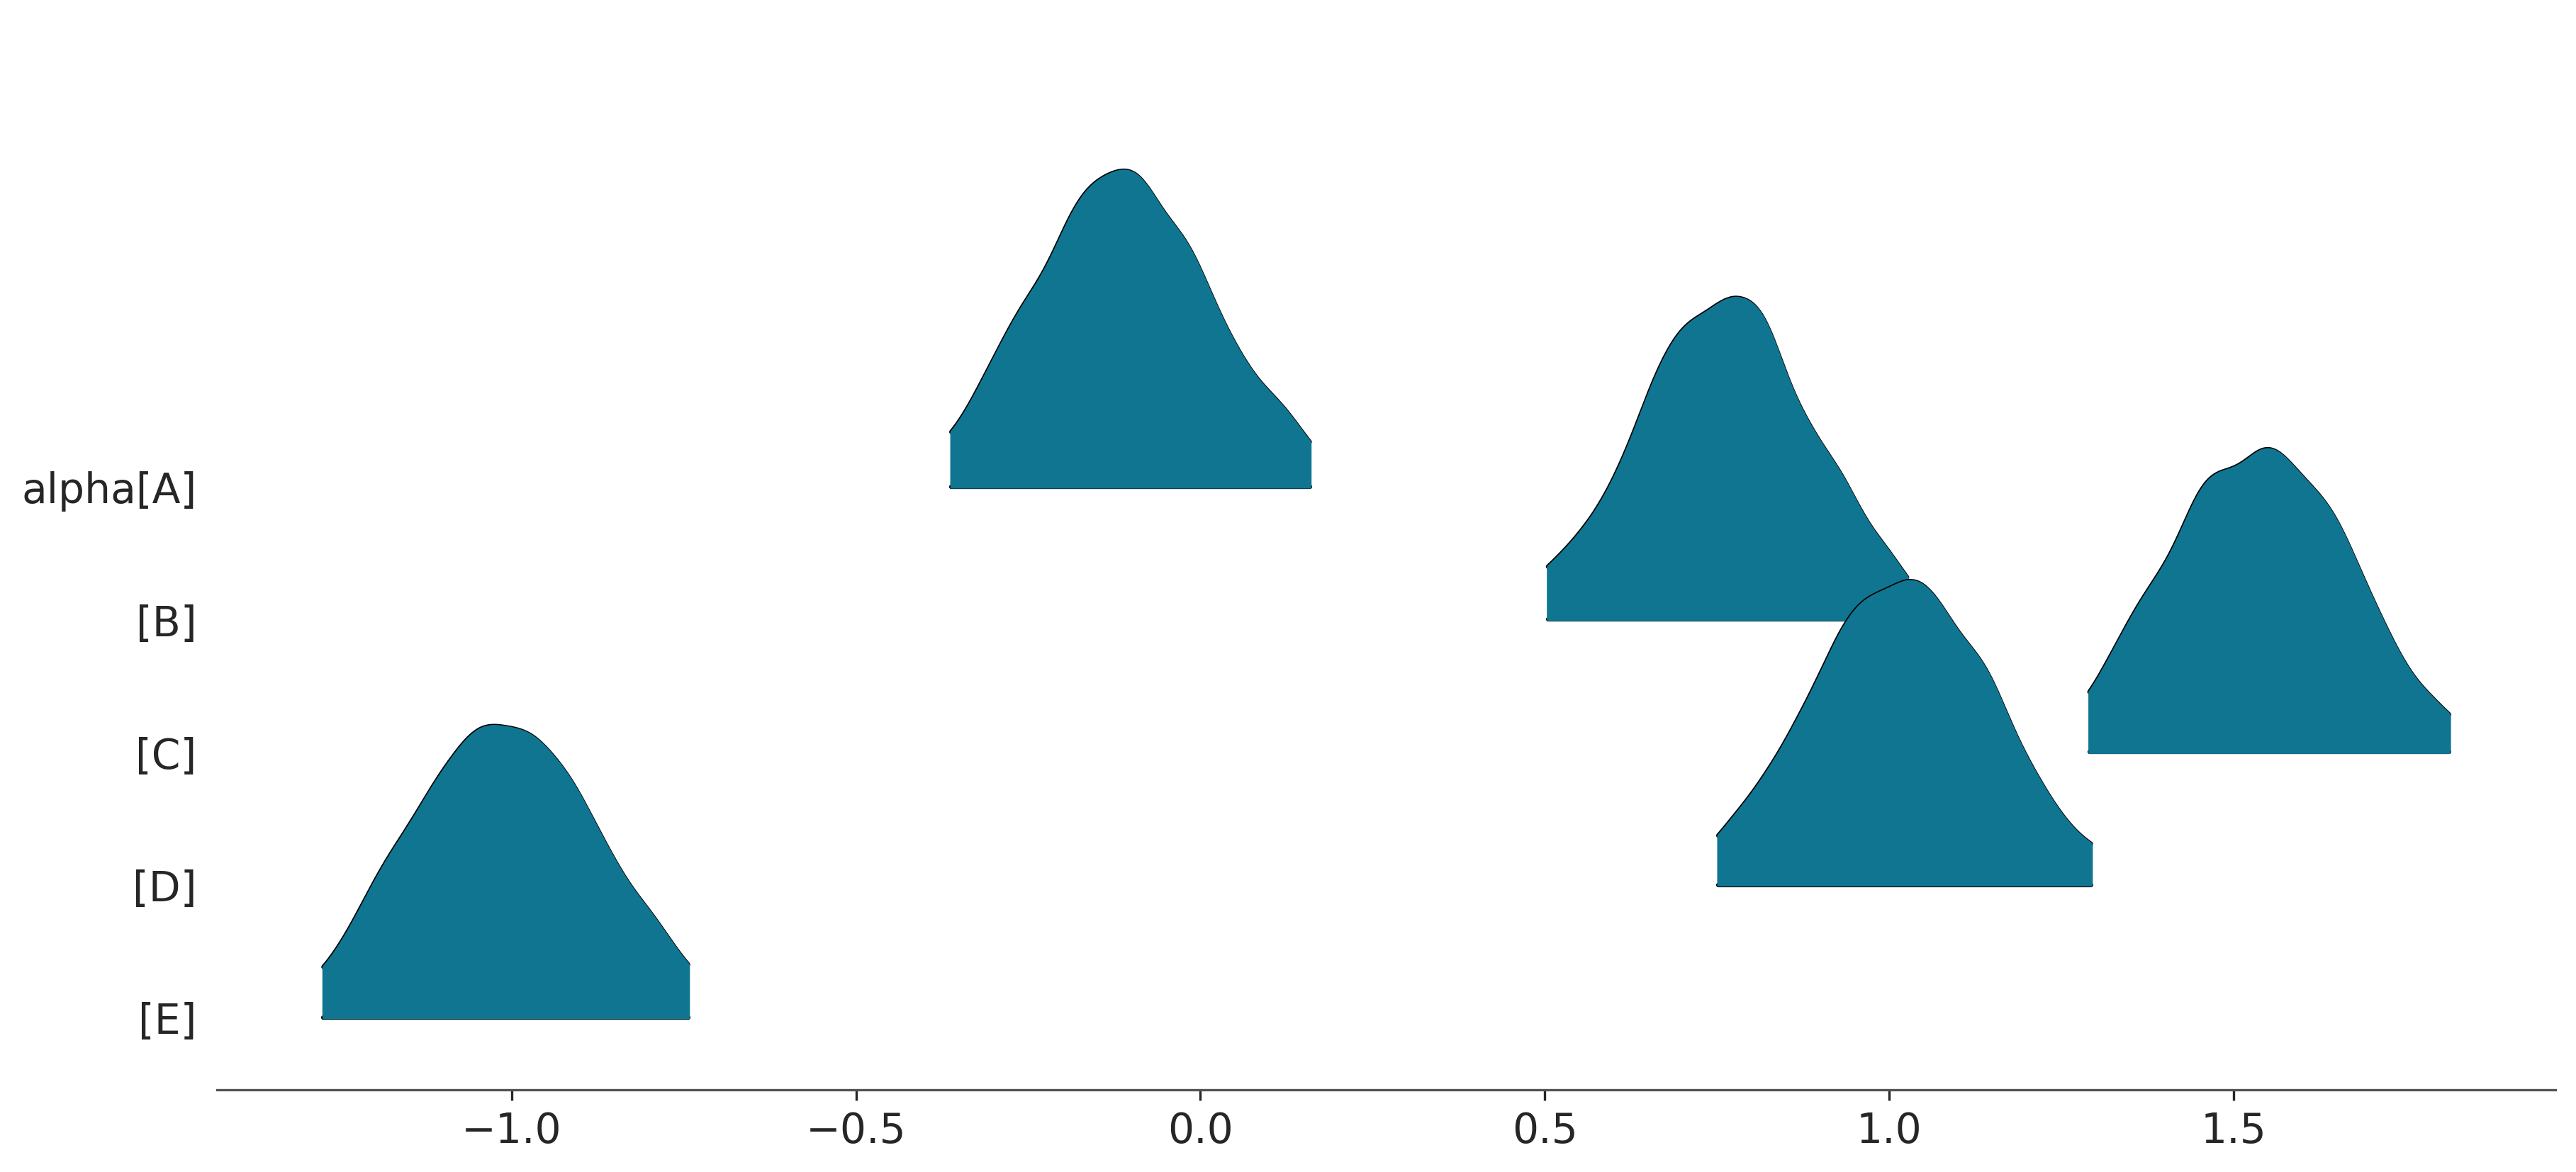

In [52]:
az.plot_forest(idata, combined=True, var_names=["alpha"], hdi_prob=0.95, kind="ridgeplot")

... yeah the above kind of looks ugly LOL ... 
to actually reproduce the `slabinterval` geom one would need to do something else ... 

In [92]:
# TODO 

## Posterior means and predictions 

In [94]:
idata.posterior['alpha_bar'].mean()

<xarray.DataArray 'alpha_bar' ()> Size: 8B
array(0.3586002)

<Axes: >

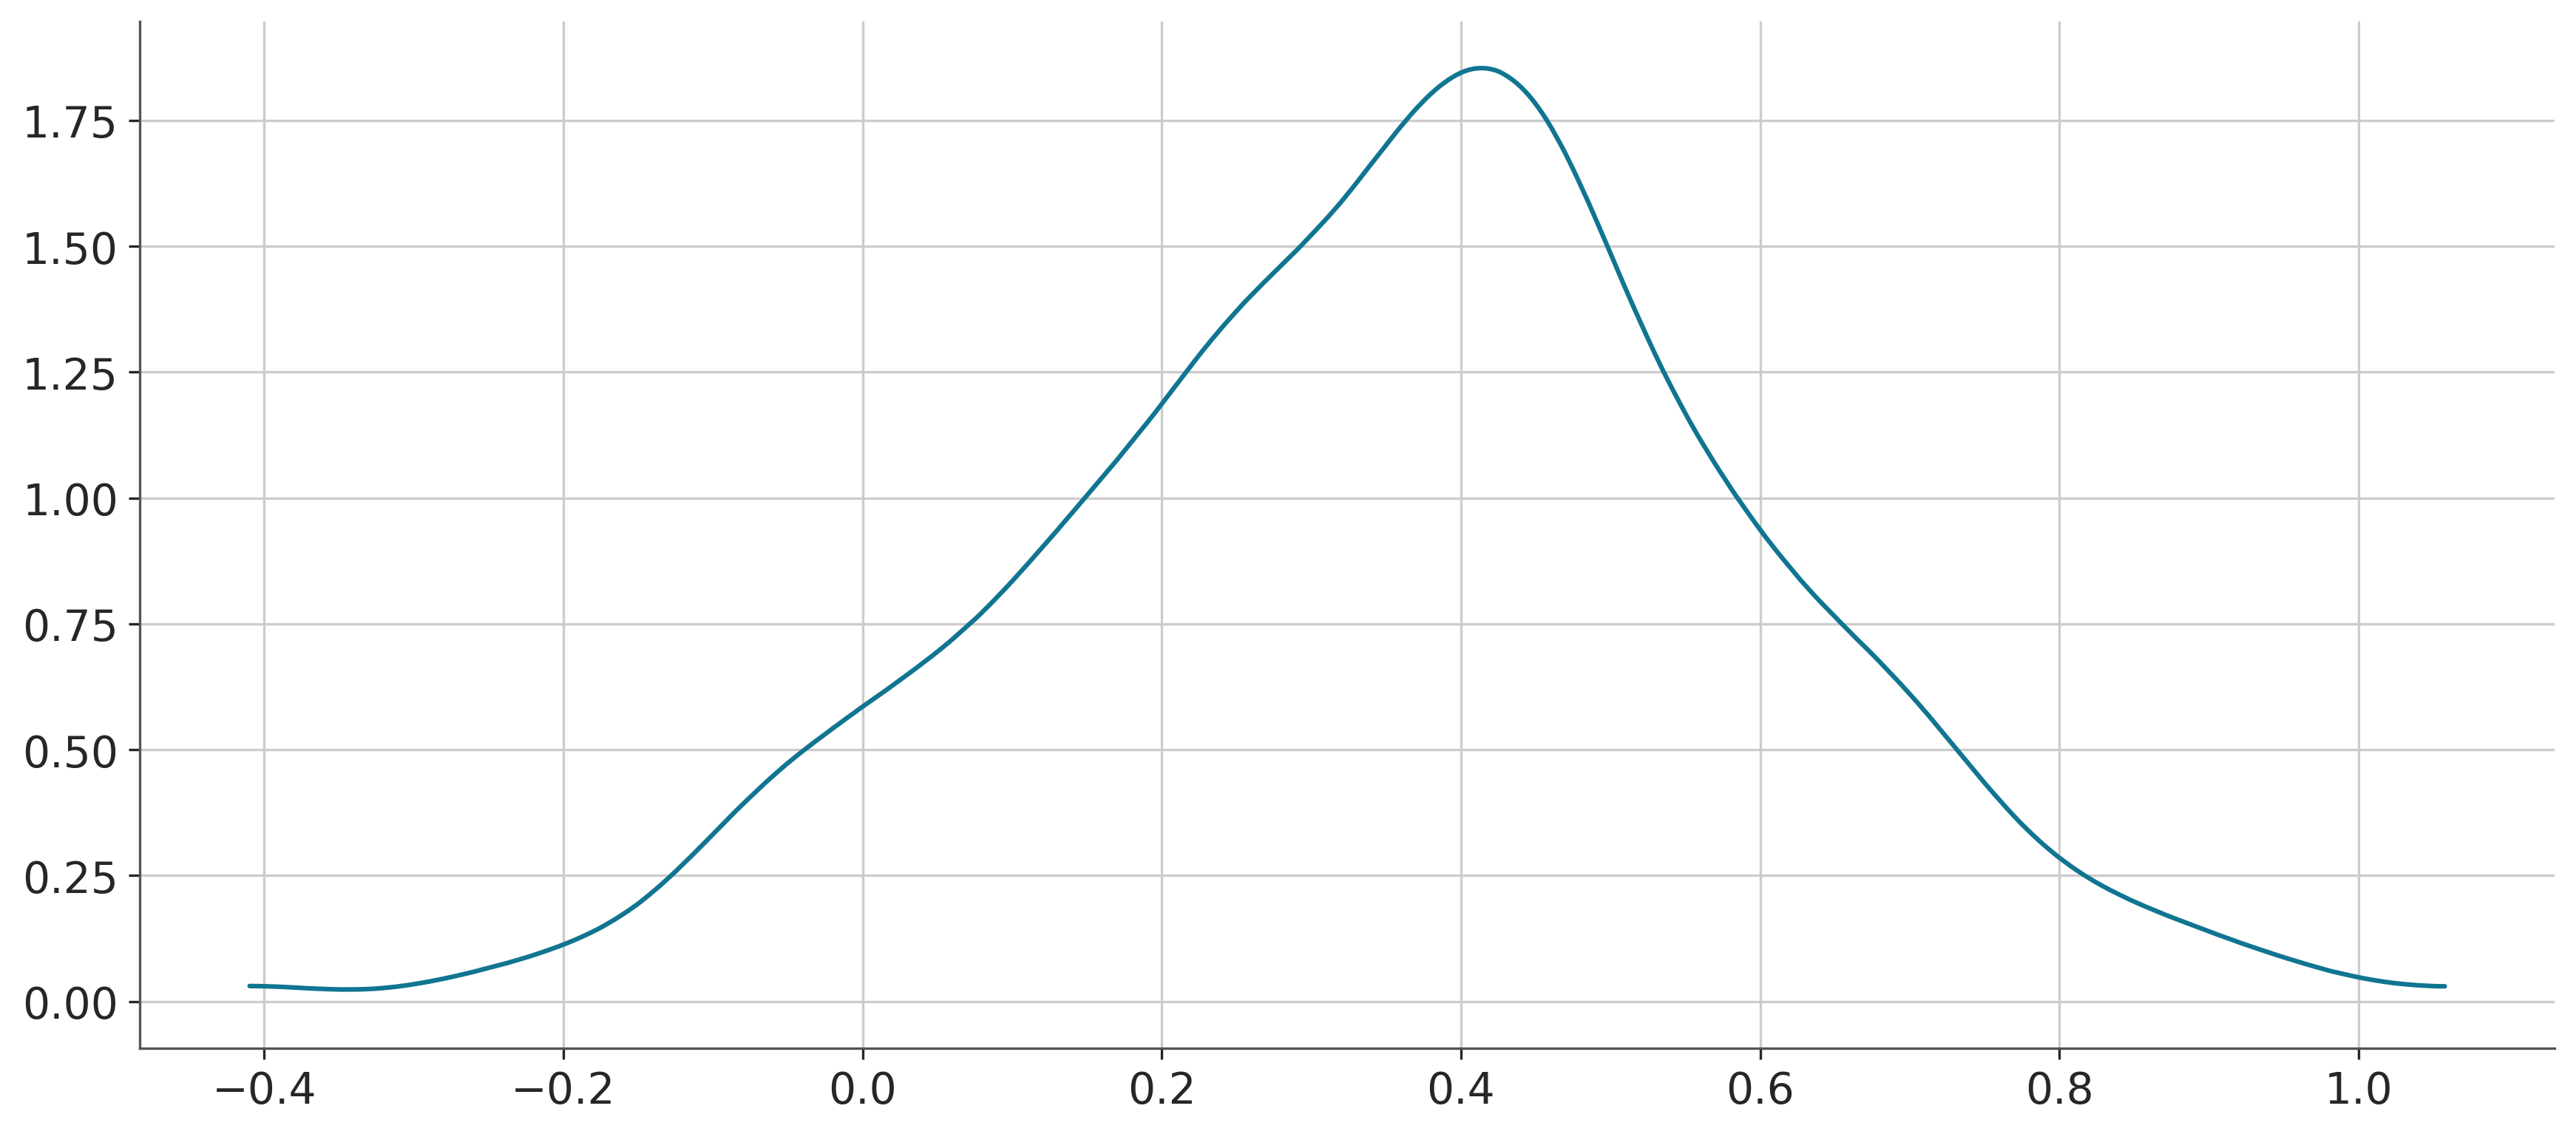

In [99]:
az.plot_dist(idata.posterior['alpha_bar'].mean(dim="chain"))